In [1]:
!pip install annoy


Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.2947 ms

Annoy NN index: [219, 898, 593]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.2793154441691197)]
Waktu Annoy: 0.0818 ms


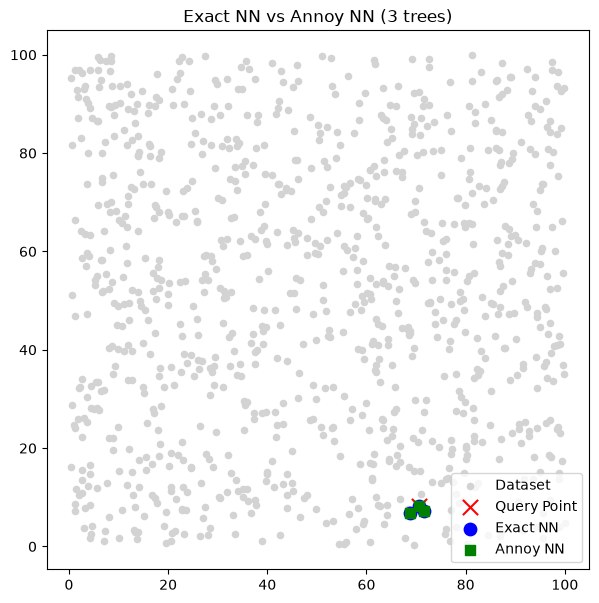

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print(f"Waktu Exact: {round(time_exact*1000, 4)} ms")

# 3. Annoy NN (3 tree)
f = 2
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print(f"Waktu Annoy: {round(time_ann*1000, 4)} ms")

# 4. Visualisasi hasil
plt.figure(figsize=(7,7))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=120, label="Query Point")
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")
plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()


**Pertanyaan:** *Kenapa code dibagian build index tidak dihitung waktunya?*  
**Jawaban/Analisis:**  
Proses *build index* dilakukan sekali secara offline (*offline batch precomputation*) di server saat katalog lagu diindeks ke database. Yang diukur dan dinilai pengguna secara real-time adalah **latensi kueri pencarian** (*online query time*).


In [3]:
# Simulasi 100k lagu x 20 fitur audio
n_tracks = 100_000
n_features = 20

np.random.seed(42)
X_sp = np.random.rand(n_tracks, n_features).astype(np.float32)
query_sp = np.random.rand(1, n_features).astype(np.float32)

from sklearn.metrics.pairwise import euclidean_distances
start = time.time()
distances = euclidean_distances(query_sp, X_sp)[0]
exact_idx = np.argsort(distances)[:5]
exact_time = time.time() - start
print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 4), "seconds")

annoy_index = AnnoyIndex(n_features, 'euclidean')
for i in range(n_tracks):
    annoy_index.add_item(i, X_sp[i])
annoy_index.build(10)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query_sp[0], 5)
annoy_time = time.time() - start
print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 4), "seconds")
print(f"Percepatan: {exact_time / annoy_time:.2f}x lebih cepat!")


Exact NN result: [51447 65143 91665  7195 98551]
Exact NN time: 0.0743 seconds
Annoy result: [51447, 85738, 80422, 63823, 87883]
Annoy time: 0.0001 seconds
Percepatan: 724.77x lebih cepat!
